# 04 - Valutazione unica: top-down, bottom-up e tutti gli esperimenti

Questo notebook legge i JSON salvati, senza rigenerare obiettivi o chiamare LM Studio. **Run All** valuta tutte le suite disponibili per default (`SUITE_IDS = None`), incluse quelle storiche e tutte le loro configurazioni e ripetizioni.

| Metodo | Input |
|---|---|
| `top_down` | Baseline in `output/top_down/` e copie congelate delle suite |
| `bottom_up` | Risultati ordinari del notebook 02 in `output/top_down_bottom_up/` |
| `<suite>/<configurazione>` | Tutte le run completate del notebook 03 |

Le nuove suite hanno sei configurazioni su dodici dataset; quelle storiche conservano il proprio disegno. I risultati restano distinti per suite, dataset, livello HLG/LLG e ripetizione. I confronti richiedono la stessa baseline e descrizione; il confronto con il riferimento richiede anche la stessa suite e ripetizione.

Le metriche principali sono Precision e Recall pesate per il numero di riferimenti, con F1 ricavata dai due aggregati. Le macro-medie sono supplementari. Le traiettorie includono la baseline a iterazione zero e soltanto checkpoint completati. Run mancanti, fallite o escluse rimangono nella copertura, senza punteggi inventati; le run completate senza convergenza sono valutate e segnalate.

La metodologia BERT, distinta dalla cosine del feedback bottom-up, è descritta in [README_evaluation.md](../docs/README_evaluation.md). Questo notebook sostituisce il precedente notebook separato per il solo confronto top-down/bottom-up.


In [1]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import json
import sys
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir() and (PROJECT_ROOT.parent / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
for directory in (PROJECT_ROOT, PROJECT_ROOT / "notebook"):
    if str(directory) not in sys.path:
        sys.path.insert(0, str(directory))

from groundtruth import GROUNDTRUTH_BY_NAME

# None = tutte le suite, storiche incluse. Per il confronto finale selezionare
# esplicitamente gli ID della campagna ofat_fixed_thresholds_<data>.
SUITE_IDS = None
EXPERIMENTS_ROOT = PROJECT_ROOT / "output" / "bottom_up_experiments"
SUITE_DIRS = (sorted(p.parent for p in EXPERIMENTS_ROOT.glob("*/manifest.json"))
              if SUITE_IDS is None else [EXPERIMENTS_ROOT / name for name in SUITE_IDS])
# Ogni evaluation ha una cartella nuova, senza sovrascrivere report precedenti.
REPORT_ID = datetime.now(ZoneInfo("Europe/Rome")).strftime("%Y%m%d_%H%M%S_%f")
REPORT_DIR = PROJECT_ROOT / "output" / "evaluation" / "configuration_comparison" / REPORT_ID
print("Suite incluse:", [p.name for p in SUITE_DIRS])
print("Bottom-up ordinaria:", PROJECT_ROOT / "output" / "top_down_bottom_up")
print("Report:", REPORT_DIR)

# Rende esplicito il disegno delle suite selezionate, senza rinominare lo storico.
suite_inventory = []
for directory in SUITE_DIRS:
    manifest = json.loads((directory / "manifest.json").read_text(encoding="utf-8"))
    suite_inventory.append({
        "suite_id": manifest["suite_id"], "design": manifest.get("design", "historical_unspecified"),
        "configurations": len(manifest["configurations"]), "datasets": len(manifest["baselines"]),
        "planned_runs": manifest.get("planned_runs"),
        "manually_confirmed_thresholds": all(
            status == "manually_confirmed" for status in
            manifest.get("threshold_selection", {}).get("selection_status", {}).values()
        ) and bool(manifest.get("threshold_selection", {}).get("selection_status")),
        "threshold_selection_source": manifest.get("threshold_selection", {}).get("selection_source"),
    })
display(pd.DataFrame(suite_inventory))


Suite incluse: ['ofat_fixed_thresholds_20261023_015718']
Bottom-up ordinaria: C:\Users\agnes\Desktop\TESI FINALE CON EXPERIMENT\LLM_MultiAgentChain_GoalOrientedAPIAlignement\output\top_down_bottom_up
Report: C:\Users\agnes\Desktop\TESI FINALE CON EXPERIMENT\LLM_MultiAgentChain_GoalOrientedAPIAlignement\output\evaluation\configuration_comparison\20261023_090732_305510


,suite_id,design,configurations,datasets,planned_runs,manually_confirmed_thresholds,threshold_selection_source
0,ofat_fixed_thresholds_20261023_015718,OFAT prompting 0/1/4 examples; evaluator tempe...,6,12,72,False,user_tested_fixed


## Funzioni di valutazione incorporate

Le celle seguenti contengono la lettura e la verifica degli output, il calcolo
dei confronti e il salvataggio dei report. Sostituiscono il modulo separato
`configuration_comparison.py`. Eseguirle prima della raccolta dei risultati.
Non avviano la pipeline e non effettuano richieste ai modelli di LM Studio.

I report conservano `reused_from` e `origin_run_directory`: i risultati riutilizzati tra suite non costituiscono nuove osservazioni indipendenti.


### Controlli e lettura delle collezioni di goal


In [2]:
from collections import Counter
import hashlib
import json
from pathlib import Path


def digest(raw):
    return hashlib.sha256(raw).hexdigest()


def baseline_key(payload):
    fields = ("description", "structuredHighLevelGoals", "structuredLowLevelGoals")
    if any(field not in payload for field in fields):
        raise ValueError("Missing verifiable initial hierarchy or description")
    return digest(json.dumps({field: payload[field] for field in fields},
                             sort_keys=True, ensure_ascii=False).encode("utf-8"))


def goal_texts(container, field):
    from src.evaluation.goal_evaluator import goal_descriptions
    return goal_descriptions(container, field)




### Raccolta degli output originali e sperimentali


In [3]:
def collect_outputs(project_root, suite_directories):
    """Keep planned/missing runs visible; read actual JSON results, never old CSVs."""
    root = Path(project_root)
    hashes, entries, availability, baselines = {}, [], [], {}
    configurations = []

    def read(path):
        path = Path(path).resolve()
        raw = path.read_bytes()
        checksum = digest(raw)
        if path in hashes and hashes[path] != checksum:
            raise ValueError(f"Input changed during collection: {path}")
        hashes[path] = checksum
        return json.loads(raw)

    def register_baseline(payload, path):
        key = baseline_key(payload)
        identity = (payload["name"], key)
        if identity not in baselines:
            entry = {"dataset": payload["name"], "baseline_key": key, "suite_id": "",
                     "method": "top_down", "config_id": "top_down", "repetition": 0,
                     "source_file": str(path), "payload": payload,
                     "hlg": payload["structuredHighLevelGoals"], "llg": payload["structuredLowLevelGoals"]}
            goal_texts(entry["hlg"], "goals")
            goal_texts(entry["llg"], "low_level_goals")
            entries.append(entry)
            baselines[identity] = entry
            availability.append({k: v for k, v in entry.items() if k not in {"payload", "hlg", "llg"}} | {"status": "completed"})
        return key

    for path in sorted((root / "output" / "top_down").glob("*_top_down.json")):
        register_baseline(read(path), path)
    for directory in map(Path, suite_directories):
        manifest = read(directory / "manifest.json")
        configurations.extend({"suite_id": manifest["suite_id"],
                               "design": manifest.get("design", "historical_unspecified"),
                               "planned_datasets": len(manifest["baselines"]),
                               "planned_repetitions": manifest["repetitions"], **config}
                              for config in manifest["configurations"])
        if manifest.get("storage_layout") == "dataset_json_v2":
            from src.bottom_up.result_storage import payload_hash, result_payload
            for baseline in manifest["baselines"]:
                payload = baseline["payload"]
                if payload_hash(payload) != baseline["sha256"]:
                    raise ValueError("Frozen compact baseline changed")
                key = register_baseline(payload, directory / "manifest.json")
                path = directory / baseline["dataset_file"]
                document = read(path) if path.exists() else None
                if document and (document["baseline_sha256"] != baseline["sha256"]
                                 or payload_hash(document["baseline"]) != baseline["sha256"]):
                    raise ValueError("Compact dataset baseline differs from the manifest")
                for config in manifest["configurations"]:
                    for repetition in range(1, manifest["repetitions"] + 1):
                        run_id = f"{config['config_id']}/repeat_{repetition:03d}"
                        record = document["runs"].get(run_id, {}) if document else {}
                        identity = dict(dataset=baseline["dataset"], baseline_key=key,
                            suite_id=manifest["suite_id"], config_id=config["config_id"],
                            method=f"{manifest['suite_id']}/{config['config_id']}", repetition=repetition)
                        row = {**identity, "status": record.get("status", "not_started"),
                               "source_file": str(path), "error": record.get("error")}
                        if row["status"] == "completed":
                            if record["experiment"] != config or record["repetition"] != repetition:
                                raise ValueError("Compact run configuration differs from the manifest")
                            result = result_payload(document, record)
                            goal_texts(result["finalHighLevelGoals"], "goals")
                            goal_texts(result["finalLowLevelGoals"], "low_level_goals")
                            entries.append({**identity, "source_file": str(path), "payload": result,
                                            "hlg": result["finalHighLevelGoals"], "llg": result["finalLowLevelGoals"]})
                        availability.append(row)
            continue
        for baseline in manifest["baselines"]:
            source = directory / baseline["snapshot"]
            payload = read(source)
            if hashes[source.resolve()] != baseline["sha256"]:
                raise ValueError(f"Frozen baseline altered: {source}")
            key = register_baseline(payload, source)
            for config in manifest["configurations"]:
                for repetition in range(1, manifest["repetitions"] + 1):
                    identity = {"dataset": baseline["dataset"], "baseline_key": key,
                        "suite_id": manifest["suite_id"], "config_id": config["config_id"],
                        "method": f"{manifest['suite_id']}/{config['config_id']}", "repetition": repetition}
                    job = directory / "runs" / config["config_id"] / f"repeat_{repetition:03d}" / baseline["dataset_id"]
                    attempts = sorted(job.glob("attempt_*/run.json"))
                    if not attempts:
                        availability.append({**identity, "status": "not_started"})
                        continue
                    run_path = attempts[-1]
                    record = read(run_path)
                    row = {**identity, "status": record["status"], "error": record.get("error"),
                           "source_file": str(run_path), "elapsed_seconds": record.get("elapsed_seconds"),
                           "reused_from": record.get("reused_from"),
                           "origin_run_directory": record.get("origin_run_directory")}
                    if record["status"] != "completed":
                        availability.append(row)
                        continue
                    result_path = run_path.parent / "result.json"
                    result = read(result_path)
                    if hashes[result_path.resolve()] != record["result_sha256"]:
                        raise ValueError(f"Result hash mismatch: {result_path}")
                    if (result.get("baselineSha256") != baseline["sha256"] or result.get("name") != baseline["dataset"]
                            or result.get("experiment") != config or result.get("repetition") != repetition):
                        raise ValueError(f"Result provenance mismatch: {result_path}")
                    goal_texts(result["finalHighLevelGoals"], "goals")
                    goal_texts(result["finalLowLevelGoals"], "low_level_goals")
                    entries.append({**identity, "source_file": str(result_path), "payload": result,
                                    "reused_from": record.get("reused_from"),
                                    "origin_run_directory": record.get("origin_run_directory"),
                                    "hlg": result["finalHighLevelGoals"], "llg": result["finalLowLevelGoals"]})
                    availability.append({**row, "source_file": str(result_path)})
    from src.bottom_up.result_storage import payload_hash, result_payload
    for path in sorted((root / "output" / "top_down_bottom_up" / "datasets").glob("*.json")):
        document = read(path)
        if payload_hash(document["baseline"]) != document["baseline_sha256"]:
            raise ValueError("Compact ordinary baseline altered")
        for record in document["runs"].values():
            identity = dict(dataset=document["name"], method="bottom_up", config_id="bottom_up",
                            suite_id="", repetition=record.get("repetition", 1), source_file=str(path))
            if record.get("status") != "completed":
                availability.append({**identity, "status": record.get("status", "not_started"),
                                     "error": record.get("error")})
                continue
            key = register_baseline(document["baseline"], path)
            result = result_payload(document, record)
            entries.append({**identity, "baseline_key": key, "payload": result,
                            "hlg": result["finalHighLevelGoals"], "llg": result["finalLowLevelGoals"]})
            availability.append({**identity, "baseline_key": key, "status": "completed"})
    for path in sorted((root / "output" / "top_down_bottom_up").glob("*.json")):
        if path.name == "results_summary.json":
            continue
        data = read(path)
        # Prefer the new dataset document when a matching legacy output is present.
        try:
            legacy_key = baseline_key(data)
        except ValueError:
            legacy_key = None
        if any(e["method"] == "bottom_up" and e["dataset"] == data.get("name")
               and e["baseline_key"] == legacy_key for e in entries):
            continue
        identity = {"dataset": data.get("name"), "method": "bottom_up",
                    "config_id": "bottom_up", "suite_id": "", "repetition": 0, "source_file": str(path)}
        try:
            if data.get("bottomUpError"):
                raise ValueError(data["bottomUpError"])
            key = baseline_key(data)
            if (data["name"], key) not in baselines:
                raise ValueError("Original output has a different/unavailable baseline")
            if any(e["method"] == "bottom_up" and e["dataset"] == data["name"] and e["baseline_key"] == key for e in entries):
                raise ValueError("Duplicate original output for the same baseline")
            goal_texts(data["finalHighLevelGoals"], "goals")
            goal_texts(data["finalLowLevelGoals"], "low_level_goals")
            entries.append({**identity, "baseline_key": key, "payload": data,
                            "hlg": data["finalHighLevelGoals"], "llg": data["finalLowLevelGoals"]})
            availability.append({**identity, "baseline_key": key, "status": "completed"})
        except (KeyError, ValueError, TypeError) as exc:
            availability.append({**identity, "status": "excluded", "error": str(exc)})
    for (dataset, key) in baselines:
        if not any(e["method"] == "bottom_up" and e["dataset"] == dataset
                   and e["baseline_key"] == key for e in entries):
            availability.append({"dataset": dataset, "baseline_key": key,
                "method": "bottom_up", "config_id": "bottom_up",
                "suite_id": "", "repetition": 0, "status": "unavailable",
                "error": "No eligible original bottom-up output for this baseline"})
    return {"entries": entries, "availability": availability, "input_hashes": hashes,
            "configurations": configurations}




### Metriche e confronti appaiati


In [4]:
def evaluate_outputs(collection, references, score_goals):
    import pandas as pd
    from src.evaluation.goal_evaluator import weighted_metric_table
    rows, iteration_rows, matches = [], [], []
    baselines = {(e["dataset"], e["baseline_key"]): e for e in collection["entries"]
                 if e["method"] == "top_down"}
    if not collection["entries"]:
        raise ValueError("No saved hierarchies to evaluate; run the execution notebooks first")
    for entry in collection["entries"]:
        identity = {k: entry[k] for k in ("dataset", "baseline_key", "suite_id", "method", "config_id", "repetition", "source_file")}
        if identity["dataset"] not in references:
            raise ValueError(f"No ground truth: {identity['dataset']}")
        cycle = entry["payload"].get("globalGoalCycle", {})
        counts = Counter()
        for trace in cycle.get("iterations", []):
            for evaluation in trace.get("evaluations", {}).values():
                votes = evaluation.get("critic_votes", {}).get("documentary", [])
                valid = [v for v in votes if v["status"] == "VALID"]
                winner = max(Counter(v["decision"] for v in valid).values(), default=0)
                counts.update(branches=1, votes=len(votes), valid_votes=len(valid), quorum=int(winner >= 2))
        status = {"reused_from": entry.get("reused_from"),
                  "origin_run_directory": entry.get("origin_run_directory"),
                  "converged": cycle.get("converged"), "completed_iterations": cycle.get("completed_iterations"),
                  "stop_reason": cycle.get("stop_reason"), "warning_count": len(cycle.get("warnings", [])),
                  "quorum_rate": counts["quorum"] / counts["branches"] if counts["branches"] else None,
                  "valid_vote_rate": counts["valid_votes"] / counts["votes"] if counts["votes"] else None}

        def score(hlg, llg, iteration=None):
            for level, container, field, ref_field in (("HLG", hlg, "goals", "highLevelGoals"),
                                                      ("LLG", llg, "low_level_goals", "lowLevelGoals")):
                preds = goal_texts(container, field)
                refs = references[identity["dataset"]][ref_field]
                result = dict(score_goals(preds, refs))
                assigned = result.pop("matches", [])
                row = {**identity, **status, "level": level, "generated_goal_count": len(preds),
                       "reference_goal_count": len(refs), **result}
                if iteration is None:
                    rows.append(row)
                    matches.extend({**identity, "level": level, **match} for match in assigned)
                else:
                    iteration_rows.append({**row, "iteration": iteration})
        score(entry["hlg"], entry["llg"])
        if entry["method"] != "top_down":
            baseline = baselines[(entry["dataset"], entry["baseline_key"])]
            score(baseline["hlg"], baseline["llg"], 0)
        for trace in cycle.get("iterations", []):
            if trace.get("checkpoint_complete") is not False:
                score(trace["high_level_goals"], trace["low_level_goals"], trace["iteration"])
    metrics = pd.DataFrame(rows)
    values = ["precision", "recall", "f1"]
    # Supplementary macros average repetitions within a dataset; weighted metrics remain primary.
    dataset_means = metrics.groupby(["method", "config_id", "suite_id", "dataset", "baseline_key", "level"], dropna=False)[values].mean().reset_index()
    macro = dataset_means.groupby(["method", "level"])[values].agg(["mean", "std", "count"])
    macro.columns = ["_".join(c) for c in macro.columns]
    deltas = []
    for comparator in ("top_down", "bottom_up", "reference"):
        if comparator == "reference":
            candidates = metrics[metrics.suite_id != ""]
            target = candidates[candidates.config_id == "reference"]
            candidates = candidates[candidates.config_id != "reference"]
            keys = ["dataset", "baseline_key", "level", "suite_id", "repetition"]
        else:
            target = metrics[metrics.method == comparator]
            candidates = metrics[metrics.method != comparator]
            keys = ["dataset", "baseline_key", "level"]
        paired = candidates.merge(target[keys + values], on=keys, how="left", validate="many_to_one", suffixes=("", "_comparator"))
        paired["comparator"] = comparator
        paired["pair_available"] = paired["f1_comparator"].notna()
        for metric in values:
            paired[f"delta_{metric}"] = paired[metric] - paired[f"{metric}_comparator"]
        deltas.append(paired)
    deltas = pd.concat(deltas, ignore_index=True)
    paired_dataset = deltas[deltas.pair_available].groupby(["method", "comparator", "dataset", "baseline_key", "level"])[
        values + [f"{v}_comparator" for v in values] + [f"delta_{v}" for v in values]].mean().reset_index()
    paired_macro = paired_dataset.groupby(["method", "comparator", "level"])[
        values + [f"{v}_comparator" for v in values] + [f"delta_{v}" for v in values]].agg(["mean", "std", "count"])
    paired_macro.columns = ["_".join(c) for c in paired_macro.columns]
    availability = pd.DataFrame(collection["availability"])
    coverage = availability.groupby(["method", "status"]).size().rename("runs").reset_index()
    variability = metrics.groupby(["method", "dataset", "baseline_key", "level"])[values].agg(["mean", "std", "count"])
    variability.columns = ["_".join(c) for c in variability.columns]
    paired_valid = deltas[deltas.pair_available]
    paired_groups = ["method", "comparator", "level"]
    paired_weighted = weighted_metric_table(paired_valid, paired_groups)
    comparator_frame = paired_valid.drop(columns=values).rename(
        columns={f"{v}_comparator": v for v in values})
    comparator_weighted = weighted_metric_table(comparator_frame, paired_groups)
    paired_weighted = paired_weighted.merge(comparator_weighted, on=paired_groups,
                                            suffixes=("", "_comparator"), validate="one_to_one")
    for value in values:
        paired_weighted[f"delta_{value}"] = paired_weighted[value] - paired_weighted[f"{value}_comparator"]
    iteration_metrics = pd.DataFrame(iteration_rows)
    return {"weighted_metrics": weighted_metric_table(metrics, ["method", "config_id", "suite_id", "level"]),
            "weighted_by_repetition": weighted_metric_table(metrics, ["method", "config_id", "suite_id", "repetition", "level"]),
            "paired_weighted_metrics": paired_weighted,
            "weighted_iteration_metrics": weighted_metric_table(iteration_metrics,
                ["method", "config_id", "suite_id", "iteration", "level"]),
            "configurations": (pd.DataFrame(collection["configurations"]) if collection.get("configurations")
                               else pd.DataFrame(columns=["suite_id", "config_id", "experiment"])),
            "availability": availability, "coverage": coverage, "metrics": metrics,
            "dataset_means": dataset_means, "macro_metrics": macro.reset_index(),
            "paired_deltas": deltas, "paired_macro": paired_macro.reset_index(),
            "repeat_variability": variability.reset_index(), "iteration_metrics": iteration_metrics,
            "matches": pd.DataFrame(matches)}




### Salvataggio dei report e della provenienza


In [5]:
def export_comparison(collection, tables, references, destination, metric_configuration):
    """Refuse mixed versions when an input is overwritten during evaluation."""
    changed = [str(path) for path, checksum in collection["input_hashes"].items()
               if not path.exists() or digest(path.read_bytes()) != checksum]
    if changed:
        raise RuntimeError(f"Inputs changed during evaluation; rerun collection: {changed}")
    destination = Path(destination)
    destination.mkdir(parents=True, exist_ok=False)
    for name, table in tables.items():
        table.to_csv(destination / f"{name}.csv", index=False, encoding="utf-8-sig")
    provenance = {"metric": metric_configuration,
        "sources": {str(p): checksum for p, checksum in collection["input_hashes"].items()},
        "ground_truth_sha256": digest(json.dumps(references, sort_keys=True, ensure_ascii=False).encode()),
        "ground_truth_snapshot": references,
        "pairing": "Identical dataset, initial hierarchy and description; reference also matches suite and repetition.",
        "aggregation": "Primary: reference-weighted P/R then harmonic F1; per-repetition tables separate. Macro averages are supplementary and explicitly named; paired tables use identical cohorts.",
        "status_policy": "All completed final outputs including nonconvergent; missing/failed/excluded only in availability.",
        "ordinary_bottom_up_configuration": {e["dataset"]: e["payload"].get("bottomUpModelConfiguration", {})
                                   for e in collection["entries"] if e["method"] == "bottom_up"}}
    (destination / "evaluation_manifest.json").write_text(json.dumps(provenance, ensure_ascii=False, indent=2), encoding="utf-8")
    return destination


## 1. Lettura e verifica dei risultati

Legge i JSON effettivi e verifica gli hash degli esperimenti. Per ogni run usa l'ultimo tentativo, senza mescolare checkpoint di tentativi precedenti. Le baseline top-down uguali sono deduplicate; se differiscono vengono mantenute come coorti separate. Le righe della pipeline originale sono ammesse solo quando gli input incorporati corrispondono a una baseline disponibile.

Se le run sono ancora in corso, il report fotografa i risultati disponibili al momento della lettura. Se un file letto viene modificato durante la valutazione, l'export si ferma: rieseguire la raccolta e il calcolo per avere input coerenti.


In [6]:
collection = collect_outputs(PROJECT_ROOT, SUITE_DIRS)
availability_df = pd.DataFrame(collection["availability"])
display(availability_df)
display(availability_df.groupby(["method", "status"]).size().rename("run_count").reset_index())
print("Gerarchie finali valutabili:", len(collection["entries"]))
print("Dataset con ground truth:", len(GROUNDTRUTH_BY_NAME))


c:\Users\agnes\Desktop\TESI FINALE CON EXPERIMENT\LLM_MultiAgentChain_GoalOrientedAPIAlignement\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,dataset,baseline_key,suite_id,method,config_id,repetition,source_file,status,error
0,Assegno Unico Universale - SIA Project 24 25,655d29cfb01e72094306a3b44db2a64cb01bd3feabc7fb...,,top_down,top_down,0,C:\Users\agnes\Desktop\TESI FINALE CON EXPERIM...,completed,NaN
1,Calculator,a2f1c98137715e89d6dfc46823883fdb72df0db4fb2a89...,,top_down,top_down,0,C:\Users\agnes\Desktop\TESI FINALE CON EXPERIM...,completed,NaN
2,Ethical Purchasing Group - SIA Project 22 23,d4bb6234f86a4802137e5fc15aa1169c5bdc67d67ed89d...,,top_down,top_down,0,C:\Users\agnes\Desktop\TESI FINALE CON EXPERIM...,completed,NaN
3,Event Organization Portal - SIA Project 21 22,59eec9713cbea92336f6e08d76a3de83f0a9d3ebd69ea6...,,top_down,top_down,0,C:\Users\agnes\Desktop\TESI FINALE CON EXPERIM...,completed,NaN
4,Fitness Tracker,35a96a7311539762a20d5c8ea6287f1f11eb3c320456eb...,,top_down,top_down,0,C:\Users\agnes\Desktop\TESI FINALE CON EXPERIM...,completed,NaN
...,...,...,...,...,...,...,...,...,...
91,La Reine Marlene - SIA Project 23 24,ee575eb36a903b8ea9a3bd9316162584c50e2a844ac05c...,,bottom_up,bottom_up,0,NaN,unavailable,No eligible original bottom-up output for this...
92,London Ambulance Service,192788d3c25f294020f69e732ebc7120da2868601cad24...,,bottom_up,bottom_up,0,NaN,unavailable,No eligible original bottom-up output for this...
93,Planning Poker,d906cccc5d515fdbc27d76d1dc47df8b201b9dba469031...,,bottom_up,bottom_up,0,NaN,unavailable,No eligible original bottom-up output for this...
94,Recycling,f478e0bcf0961344e70c714b40e02f8441f3395737f42e...,,bottom_up,bottom_up,0,NaN,unavailable,No eligible original bottom-up output for this...


,method,status,run_count
0,bottom_up,unavailable,12
1,ofat_fixed_thresholds_20261023_015718/E1_0_exa...,completed,12
2,ofat_fixed_thresholds_20261023_015718/E1_1_exa...,completed,12
3,ofat_fixed_thresholds_20261023_015718/E2_tempe...,completed,12
4,ofat_fixed_thresholds_20261023_015718/E2_tempe...,completed,12
5,ofat_fixed_thresholds_20261023_015718/E2_tempe...,completed,12
6,ofat_fixed_thresholds_20261023_015718/reference,completed,12
7,top_down,completed,12


Gerarchie finali valutabili: 84
Dataset con ground truth: 12


## Valutazione con la metrica originale

Si usa `src/evaluation/goal_evaluator.py`: descrizioni HLG/LLG, preprocessing NLTK originale, BERT-base-uncased, masked mean pooling, normalizzazione L2 e assegnamento Hungarian. Tutte le similarita assegnate contribuiscono a Precision e Recall, senza soglie. Il preprocessing e disabilitato per i nomi degli attori quando valutati. I riepiloghi `weighted_*` usano i conteggi di riferimento e ricavano F1 da Precision e Recall aggregate; le macro-medie restano analisi separate. I risultati salvati prima di questa modifica devono essere ricalcolati.


In [7]:
from src.evaluation.goal_evaluator import GoalEvaluator
from src.evaluation.goal_evaluator import weighted_metric_table

BERT_MODEL_NAME = "bert-base-uncased"
# Original NLTK preprocessing for HLG/LLG descriptions; no match threshold.
evaluator = GoalEvaluator(model_name=BERT_MODEL_NAME, preprocess=True)
model = evaluator.model
METRIC_CONFIGURATION = {
    "model": BERT_MODEL_NAME,
    "resolved_revision": getattr(model.config, "_commit_hash", None),
    "pooling": "attention-mask mean pooling of last_hidden_state",
    "matching": "linear_sum_assignment(-sim_matrix); every assigned cosine contributes",
    "goal_text": "description", "similarity_threshold": None,
    "preprocessing": "NLTK tokenize; English stopwords; alphanumeric; Porter; WordNet",
    "actor_preprocessing": False,
    "scoring": "original soft P/R; harmonic F1; no clipping or threshold",
    "aggregation": "reference-count-weighted P/R, then harmonic F1; macro tables are separate",
}
score_with_matches = evaluator.score_goals

tables = evaluate_outputs(collection, GROUNDTRUTH_BY_NAME, score_with_matches)


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1213.22it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


## 3. Metriche per dataset e riepiloghi

`metrics` contiene tutte le esecuzioni finali per HLG/LLG, con convergenza, warning, quorum e validita dei voti quando disponibili. `dataset_means` media le ripetizioni prima della macro-media. `repeat_variability` separa la variabilita tra ripetizioni dello stesso dataset dalla deviazione standard tra dataset riportata nei riepiloghi macro. Con una sola ripetizione la prima non e stimabile.


In [8]:
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(tables["weighted_metrics"])
    display(tables["weighted_by_repetition"])
    display(tables["metrics"])
    display(tables["macro_metrics"])
    display(tables["repeat_variability"])

# Una colonna per ciascun metodo, una riga per dataset/livello/coorte iniziale.
f1_by_dataset = tables["dataset_means"].pivot_table(
    index=["dataset", "baseline_key", "level"], columns="method", values="f1")
display(f1_by_dataset)
tables["f1_by_dataset"] = f1_by_dataset.reset_index()


,method,config_id,suite_id,level,precision,recall,f1,reference_goal_count,dataset_count,aggregation
0,ofat_fixed_thresholds_20261023_015718/E1_0_exa...,E1_0_examples,ofat_fixed_thresholds_20261023_015718,HLG,0.618731,0.519311,0.564678,59,12,reference_weighted_precision_recall_harmonic_f1
1,ofat_fixed_thresholds_20261023_015718/E1_0_exa...,E1_0_examples,ofat_fixed_thresholds_20261023_015718,LLG,0.733727,0.427167,0.539970,259,12,reference_weighted_precision_recall_harmonic_f1
2,ofat_fixed_thresholds_20261023_015718/E1_1_exa...,E1_1_examples,ofat_fixed_thresholds_20261023_015718,HLG,0.618990,0.539194,0.576343,59,12,reference_weighted_precision_recall_harmonic_f1
3,ofat_fixed_thresholds_20261023_015718/E1_1_exa...,E1_1_examples,ofat_fixed_thresholds_20261023_015718,LLG,0.732237,0.453707,0.560264,259,12,reference_weighted_precision_recall_harmonic_f1
4,ofat_fixed_thresholds_20261023_015718/E2_tempe...,E2_temperature_0.0,ofat_fixed_thresholds_20261023_015718,HLG,0.603070,0.516495,0.556435,59,12,reference_weighted_precision_recall_harmonic_f1
5,ofat_fixed_thresholds_20261023_015718/E2_tempe...,E2_temperature_0.0,ofat_fixed_thresholds_20261023_015718,LLG,0.734590,0.429590,0.542137,259,12,reference_weighted_precision_recall_harmonic_f1
6,ofat_fixed_thresholds_20261023_015718/E2_tempe...,E2_temperature_0.4,ofat_fixed_thresholds_20261023_015718,HLG,0.618880,0.532485,0.572441,59,12,reference_weighted_precision_recall_harmonic_f1
7,ofat_fixed_thresholds_20261023_015718/E2_tempe...,E2_temperature_0.4,ofat_fixed_thresholds_20261023_015718,LLG,0.739967,0.438297,0.550514,259,12,reference_weighted_precision_recall_harmonic_f1
8,ofat_fixed_thresholds_20261023_015718/E2_tempe...,E2_temperature_0.6,ofat_fixed_thresholds_20261023_015718,HLG,0.601608,0.558233,0.579109,59,12,reference_weighted_precision_recall_harmonic_f1
9,ofat_fixed_thresholds_20261023_015718/E2_tempe...,E2_temperature_0.6,ofat_fixed_thresholds_20261023_015718,LLG,0.737441,0.443015,0.553510,259,12,reference_weighted_precision_recall_harmonic_f1


,method,config_id,suite_id,repetition,level,precision,recall,f1,reference_goal_count,dataset_count,aggregation
0,ofat_fixed_thresholds_20261023_015718/E1_0_exa...,E1_0_examples,ofat_fixed_thresholds_20261023_015718,1,HLG,0.618731,0.519311,0.564678,59,12,reference_weighted_precision_recall_harmonic_f1
1,ofat_fixed_thresholds_20261023_015718/E1_0_exa...,E1_0_examples,ofat_fixed_thresholds_20261023_015718,1,LLG,0.733727,0.427167,0.539970,259,12,reference_weighted_precision_recall_harmonic_f1
2,ofat_fixed_thresholds_20261023_015718/E1_1_exa...,E1_1_examples,ofat_fixed_thresholds_20261023_015718,1,HLG,0.618990,0.539194,0.576343,59,12,reference_weighted_precision_recall_harmonic_f1
3,ofat_fixed_thresholds_20261023_015718/E1_1_exa...,E1_1_examples,ofat_fixed_thresholds_20261023_015718,1,LLG,0.732237,0.453707,0.560264,259,12,reference_weighted_precision_recall_harmonic_f1
4,ofat_fixed_thresholds_20261023_015718/E2_tempe...,E2_temperature_0.0,ofat_fixed_thresholds_20261023_015718,1,HLG,0.603070,0.516495,0.556435,59,12,reference_weighted_precision_recall_harmonic_f1
5,ofat_fixed_thresholds_20261023_015718/E2_tempe...,E2_temperature_0.0,ofat_fixed_thresholds_20261023_015718,1,LLG,0.734590,0.429590,0.542137,259,12,reference_weighted_precision_recall_harmonic_f1
6,ofat_fixed_thresholds_20261023_015718/E2_tempe...,E2_temperature_0.4,ofat_fixed_thresholds_20261023_015718,1,HLG,0.618880,0.532485,0.572441,59,12,reference_weighted_precision_recall_harmonic_f1
7,ofat_fixed_thresholds_20261023_015718/E2_tempe...,E2_temperature_0.4,ofat_fixed_thresholds_20261023_015718,1,LLG,0.739967,0.438297,0.550514,259,12,reference_weighted_precision_recall_harmonic_f1
8,ofat_fixed_thresholds_20261023_015718/E2_tempe...,E2_temperature_0.6,ofat_fixed_thresholds_20261023_015718,1,HLG,0.601608,0.558233,0.579109,59,12,reference_weighted_precision_recall_harmonic_f1
9,ofat_fixed_thresholds_20261023_015718/E2_tempe...,E2_temperature_0.6,ofat_fixed_thresholds_20261023_015718,1,LLG,0.737441,0.443015,0.553510,259,12,reference_weighted_precision_recall_harmonic_f1


,dataset,baseline_key,suite_id,method,config_id,repetition,source_file,reused_from,origin_run_directory,converged,completed_iterations,stop_reason,warning_count,quorum_rate,valid_vote_rate,level,generated_goal_count,reference_goal_count,precision,recall,f1,total_similarity,matched_goal_count
0,Assegno Unico Universale - SIA Project 24 25,655d29cfb01e72094306a3b44db2a64cb01bd3feabc7fb...,,top_down,top_down,0,C:\Users\agnes\Desktop\TESI FINALE CON EXPERIM...,None,None,None,NaN,NaN,0,NaN,NaN,HLG,10,4,0.310417,0.776042,0.443452,3.104167,4
1,Assegno Unico Universale - SIA Project 24 25,655d29cfb01e72094306a3b44db2a64cb01bd3feabc7fb...,,top_down,top_down,0,C:\Users\agnes\Desktop\TESI FINALE CON EXPERIM...,None,None,None,NaN,NaN,0,NaN,NaN,LLG,24,28,0.783843,0.671865,0.723547,18.812229,24
2,Calculator,a2f1c98137715e89d6dfc46823883fdb72df0db4fb2a89...,,top_down,top_down,0,C:\Users\agnes\Desktop\TESI FINALE CON EXPERIM...,None,None,None,NaN,NaN,0,NaN,NaN,HLG,1,2,0.804847,0.402424,0.536565,0.804847,1
3,Calculator,a2f1c98137715e89d6dfc46823883fdb72df0db4fb2a89...,,top_down,top_down,0,C:\Users\agnes\Desktop\TESI FINALE CON EXPERIM...,None,None,None,NaN,NaN,0,NaN,NaN,LLG,5,7,0.729928,0.521377,0.608273,3.649638,5
4,Ethical Purchasing Group - SIA Project 22 23,d4bb6234f86a4802137e5fc15aa1169c5bdc67d67ed89d...,,top_down,top_down,0,C:\Users\agnes\Desktop\TESI FINALE CON EXPERIM...,None,None,None,NaN,NaN,0,NaN,NaN,HLG,9,4,0.300925,0.677080,0.416665,2.708321,4
5,Ethical Purchasing Group - SIA Project 22 23,d4bb6234f86a4802137e5fc15aa1169c5bdc67d67ed89d...,,top_down,top_down,0,C:\Users\agnes\Desktop\TESI FINALE CON EXPERIM...,None,None,None,NaN,NaN,0,NaN,NaN,LLG,22,14,0.416193,0.654017,0.508680,9.156240,14
6,Event Organization Portal - SIA Project 21 22,59eec9713cbea92336f6e08d76a3de83f0a9d3ebd69ea6...,,top_down,top_down,0,C:\Users\agnes\Desktop\TESI FINALE CON EXPERIM...,None,None,None,NaN,NaN,0,NaN,NaN,HLG,3,4,0.645367,0.484025,0.553171,1.936100,3
7,Event Organization Portal - SIA Project 21 22,59eec9713cbea92336f6e08d76a3de83f0a9d3ebd69ea6...,,top_down,top_down,0,C:\Users\agnes\Desktop\TESI FINALE CON EXPERIM...,None,None,None,NaN,NaN,0,NaN,NaN,LLG,10,28,0.732540,0.261622,0.385548,7.325405,10
8,Fitness Tracker,35a96a7311539762a20d5c8ea6287f1f11eb3c320456eb...,,top_down,top_down,0,C:\Users\agnes\Desktop\TESI FINALE CON EXPERIM...,None,None,None,NaN,NaN,0,NaN,NaN,HLG,7,6,0.579844,0.676485,0.624448,4.058911,6
9,Fitness Tracker,35a96a7311539762a20d5c8ea6287f1f11eb3c320456eb...,,top_down,top_down,0,C:\Users\agnes\Desktop\TESI FINALE CON EXPERIM...,None,None,None,NaN,NaN,0,NaN,NaN,LLG,17,13,0.554804,0.725513,0.628778,9.431671,13


,method,level,precision_mean,precision_std,precision_count,recall_mean,recall_std,recall_count,f1_mean,f1_std,f1_count
0,ofat_fixed_thresholds_20261023_015718/E1_0_exa...,HLG,0.593291,0.164918,12,0.566253,0.192747,12,0.533436,0.107761,12
1,ofat_fixed_thresholds_20261023_015718/E1_0_exa...,LLG,0.673025,0.193165,12,0.487567,0.211079,12,0.507880,0.172363,12
2,ofat_fixed_thresholds_20261023_015718/E1_1_exa...,HLG,0.601207,0.153664,12,0.575016,0.186583,12,0.547325,0.111338,12
3,ofat_fixed_thresholds_20261023_015718/E1_1_exa...,LLG,0.671940,0.181234,12,0.504326,0.178609,12,0.531077,0.128728,12
4,ofat_fixed_thresholds_20261023_015718/E2_tempe...,HLG,0.581395,0.161047,12,0.564376,0.196056,12,0.526597,0.105973,12
5,ofat_fixed_thresholds_20261023_015718/E2_tempe...,LLG,0.668385,0.202681,12,0.484654,0.179514,12,0.508154,0.140729,12
6,ofat_fixed_thresholds_20261023_015718/E2_tempe...,HLG,0.594028,0.164552,12,0.570113,0.187055,12,0.537596,0.107315,12
7,ofat_fixed_thresholds_20261023_015718/E2_tempe...,LLG,0.679549,0.193516,12,0.491909,0.187438,12,0.519751,0.159439,12
8,ofat_fixed_thresholds_20261023_015718/E2_tempe...,HLG,0.580586,0.161972,12,0.584205,0.187716,12,0.538665,0.109017,12
9,ofat_fixed_thresholds_20261023_015718/E2_tempe...,LLG,0.677264,0.185059,12,0.496701,0.199706,12,0.520296,0.156781,12


,method,dataset,baseline_key,level,precision_mean,precision_std,precision_count,recall_mean,recall_std,recall_count,f1_mean,f1_std,f1_count
0,ofat_fixed_thresholds_20261023_015718/E1_0_exa...,Assegno Unico Universale - SIA Project 24 25,655d29cfb01e72094306a3b44db2a64cb01bd3feabc7fb...,HLG,0.310417,NaN,1,0.776042,NaN,1,0.443452,NaN,1
1,ofat_fixed_thresholds_20261023_015718/E1_0_exa...,Assegno Unico Universale - SIA Project 24 25,655d29cfb01e72094306a3b44db2a64cb01bd3feabc7fb...,LLG,0.783843,NaN,1,0.671865,NaN,1,0.723547,NaN,1
2,ofat_fixed_thresholds_20261023_015718/E1_0_exa...,Calculator,a2f1c98137715e89d6dfc46823883fdb72df0db4fb2a89...,HLG,0.804847,NaN,1,0.402424,NaN,1,0.536565,NaN,1
3,ofat_fixed_thresholds_20261023_015718/E1_0_exa...,Calculator,a2f1c98137715e89d6dfc46823883fdb72df0db4fb2a89...,LLG,0.729928,NaN,1,0.521377,NaN,1,0.608273,NaN,1
4,ofat_fixed_thresholds_20261023_015718/E1_0_exa...,Ethical Purchasing Group - SIA Project 22 23,d4bb6234f86a4802137e5fc15aa1169c5bdc67d67ed89d...,HLG,0.301747,NaN,1,0.678931,NaN,1,0.417804,NaN,1
5,ofat_fixed_thresholds_20261023_015718/E1_0_exa...,Ethical Purchasing Group - SIA Project 22 23,d4bb6234f86a4802137e5fc15aa1169c5bdc67d67ed89d...,LLG,0.380952,NaN,1,0.653060,NaN,1,0.481202,NaN,1
6,ofat_fixed_thresholds_20261023_015718/E1_0_exa...,Event Organization Portal - SIA Project 21 22,59eec9713cbea92336f6e08d76a3de83f0a9d3ebd69ea6...,HLG,0.645367,NaN,1,0.484025,NaN,1,0.553171,NaN,1
7,ofat_fixed_thresholds_20261023_015718/E1_0_exa...,Event Organization Portal - SIA Project 21 22,59eec9713cbea92336f6e08d76a3de83f0a9d3ebd69ea6...,LLG,0.732540,NaN,1,0.261622,NaN,1,0.385548,NaN,1
8,ofat_fixed_thresholds_20261023_015718/E1_0_exa...,Fitness Tracker,35a96a7311539762a20d5c8ea6287f1f11eb3c320456eb...,HLG,0.664319,NaN,1,0.664319,NaN,1,0.664319,NaN,1
9,ofat_fixed_thresholds_20261023_015718/E1_0_exa...,Fitness Tracker,35a96a7311539762a20d5c8ea6287f1f11eb3c320456eb...,LLG,0.641794,NaN,1,0.691162,NaN,1,0.665564,NaN,1


method                                                                                                  ofat_fixed_thresholds_20261023_015718/E1_0_examples  \
dataset                                       baseline_key                                       level                                                        
Assegno Unico Universale - SIA Project 24 25  655d29cfb01e72094306a3b44db2a64cb01bd3feabc7fbb... HLG                                             0.443452     
                                                                                                 LLG                                             0.723547     
Calculator                                    a2f1c98137715e89d6dfc46823883fdb72df0db4fb2a89f... HLG                                             0.536565     
                                                                                                 LLG                                             0.608273     
Ethical Purchasing Group - SIA Project 22 23  d4bb6234f86a4802137e5fc15aa1169c5bdc67d67ed89d3... HLG                                             0.417804     
                                                                                                 LLG                                             0.481202     
Event Organization Portal - SIA Project 21 22 59eec9713cbea92336f6e08d76a3de83f0a9d3ebd69ea63... HLG                                             0.553171     
                                                                                                 LLG                                             0.385548     
Fitness Tracker                               35a96a7311539762a20d5c8ea6287f1f11eb3c320456eb0... HLG                                             0.664319     
                                                                                                 LLG                                             0.665564     
Genome Nexus                                  d66bb45bb28d3218827a5c455470ae9fe069c1a2088d0b5... HLG                                             0.542830     
                                                                                                 LLG                                             0.362457     
Gestao Hospital                               dcce92155a8af9e0828dec3a956e58df4ce351e001638c4... HLG                                             0.683576     
                                                                                                 LLG                                             0.683411     
La Reine Marlene - SIA Project 23 24          ee575eb36a903b8ea9a3bd9316162584c50e2a844ac05c6... HLG                                             0.331109     
                                                                                                 LLG                                             0.354553     
London Ambulance Service                      192788d3c25f294020f69e732ebc7120da2868601cad24a... HLG                                             0.519584     
                                                                                                 LLG                                             0.293712     
Planning Poker                                d906cccc5d515fdbc27d76d1dc47df8b201b9dba469031d... HLG                                             0.500818     
                                                                                                 LLG                                             0.255694     
Recycling                                     f478e0bcf0961344e70c714b40e02f8441f3395737f42e9... HLG                                             0.687544     
                                                                                                 LLG                                             0.709810     
SIA Project 25 26                             4d0b12df71aff78aead4c652cd8a891cf07a337e1aa7172... HLG                                             0.520460     
                         

## 4. Confronti appaiati: originale, top-down e riferimento

Ogni output viene confrontato con **top_down** e **bottom_up** sullo stesso dataset, baseline e livello. Ogni alternativa sperimentale viene anche confrontata con **reference** della stessa suite e ripetizione.

`pair_available=False` indica un confronto mancante: non viene trasformato in un delta pari a zero. `paired_macro` riporta medie e delta su coppie effettivamente disponibili e sulla stessa coorte. Una tabella macro descrittiva su dataset differenti non basta a stabilire quale metodo sia migliore.


In [9]:
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(tables["paired_weighted_metrics"])
    display(tables["paired_macro"])
    display(tables["paired_deltas"][["dataset", "method", "repetition", "level", "comparator",
                                     "pair_available", "f1", "f1_comparator", "delta_f1"]])
missing_pairs = tables["paired_deltas"][~tables["paired_deltas"]["pair_available"]]
print("Confronti senza coppia disponibile:", len(missing_pairs))


,method,comparator,level,precision,recall,f1,reference_goal_count,dataset_count,aggregation,precision_comparator,recall_comparator,f1_comparator,reference_goal_count_comparator,dataset_count_comparator,aggregation_comparator,delta_precision,delta_recall,delta_f1
0,ofat_fixed_thresholds_20261023_015718/E1_0_exa...,reference,HLG,0.618731,0.519311,0.564678,59,12,reference_weighted_precision_recall_harmonic_f1,0.624352,0.537938,0.577933,59,12,reference_weighted_precision_recall_harmonic_f1,-0.005621,-0.018627,-0.013255
1,ofat_fixed_thresholds_20261023_015718/E1_0_exa...,reference,LLG,0.733727,0.427167,0.539970,259,12,reference_weighted_precision_recall_harmonic_f1,0.739088,0.439684,0.551363,259,12,reference_weighted_precision_recall_harmonic_f1,-0.005362,-0.012517,-0.011393
2,ofat_fixed_thresholds_20261023_015718/E1_0_exa...,top_down,HLG,0.618731,0.519311,0.564678,59,12,reference_weighted_precision_recall_harmonic_f1,0.603494,0.532576,0.565822,59,12,reference_weighted_precision_recall_harmonic_f1,0.015237,-0.013266,-0.001144
3,ofat_fixed_thresholds_20261023_015718/E1_0_exa...,top_down,LLG,0.733727,0.427167,0.539970,259,12,reference_weighted_precision_recall_harmonic_f1,0.736847,0.401345,0.519649,259,12,reference_weighted_precision_recall_harmonic_f1,-0.003120,0.025822,0.020321
4,ofat_fixed_thresholds_20261023_015718/E1_1_exa...,reference,HLG,0.618990,0.539194,0.576343,59,12,reference_weighted_precision_recall_harmonic_f1,0.624352,0.537938,0.577933,59,12,reference_weighted_precision_recall_harmonic_f1,-0.005362,0.001256,-0.001589
5,ofat_fixed_thresholds_20261023_015718/E1_1_exa...,reference,LLG,0.732237,0.453707,0.560264,259,12,reference_weighted_precision_recall_harmonic_f1,0.739088,0.439684,0.551363,259,12,reference_weighted_precision_recall_harmonic_f1,-0.006852,0.014023,0.008902
6,ofat_fixed_thresholds_20261023_015718/E1_1_exa...,top_down,HLG,0.618990,0.539194,0.576343,59,12,reference_weighted_precision_recall_harmonic_f1,0.603494,0.532576,0.565822,59,12,reference_weighted_precision_recall_harmonic_f1,0.015496,0.006617,0.010521
7,ofat_fixed_thresholds_20261023_015718/E1_1_exa...,top_down,LLG,0.732237,0.453707,0.560264,259,12,reference_weighted_precision_recall_harmonic_f1,0.736847,0.401345,0.519649,259,12,reference_weighted_precision_recall_harmonic_f1,-0.004610,0.052362,0.040616
8,ofat_fixed_thresholds_20261023_015718/E2_tempe...,reference,HLG,0.603070,0.516495,0.556435,59,12,reference_weighted_precision_recall_harmonic_f1,0.624352,0.537938,0.577933,59,12,reference_weighted_precision_recall_harmonic_f1,-0.021282,-0.021443,-0.021497
9,ofat_fixed_thresholds_20261023_015718/E2_tempe...,reference,LLG,0.734590,0.429590,0.542137,259,12,reference_weighted_precision_recall_harmonic_f1,0.739088,0.439684,0.551363,259,12,reference_weighted_precision_recall_harmonic_f1,-0.004499,-0.010094,-0.009226


,method,comparator,level,precision_mean,precision_std,precision_count,recall_mean,recall_std,recall_count,f1_mean,f1_std,f1_count,precision_comparator_mean,precision_comparator_std,precision_comparator_count,recall_comparator_mean,recall_comparator_std,recall_comparator_count,f1_comparator_mean,f1_comparator_std,f1_comparator_count,delta_precision_mean,delta_precision_std,delta_precision_count,delta_recall_mean,delta_recall_std,delta_recall_count,delta_f1_mean,delta_f1_std,delta_f1_count
0,ofat_fixed_thresholds_20261023_015718/E1_0_exa...,reference,HLG,0.593291,0.164918,12,0.566253,0.192747,12,0.533436,0.107761,12,0.601040,0.169457,12,0.575579,0.187321,12,0.544511,0.116243,12,-0.007748,0.038409,12,-0.009325,0.033887,12,-0.011075,0.027556,12
1,ofat_fixed_thresholds_20261023_015718/E1_0_exa...,reference,LLG,0.673025,0.193165,12,0.487567,0.211079,12,0.507880,0.172363,12,0.687914,0.159120,12,0.489416,0.189826,12,0.529198,0.137857,12,-0.014889,0.045093,12,-0.001848,0.075474,12,-0.021318,0.069983,12
2,ofat_fixed_thresholds_20261023_015718/E1_0_exa...,top_down,HLG,0.593291,0.164918,12,0.566253,0.192747,12,0.533436,0.107761,12,0.579407,0.165047,12,0.572483,0.186963,12,0.529718,0.098039,12,0.013884,0.034655,12,-0.006230,0.021278,12,0.003718,0.026318,12
3,ofat_fixed_thresholds_20261023_015718/E1_0_exa...,top_down,LLG,0.673025,0.193165,12,0.487567,0.211079,12,0.507880,0.172363,12,0.686571,0.156074,12,0.467491,0.200827,12,0.508339,0.127696,12,-0.013546,0.058924,12,0.020076,0.071399,12,-0.000458,0.079166,12
4,ofat_fixed_thresholds_20261023_015718/E1_1_exa...,reference,HLG,0.601207,0.153664,12,0.575016,0.186583,12,0.547325,0.111338,12,0.601040,0.169457,12,0.575579,0.187321,12,0.544511,0.116243,12,0.000167,0.050512,12,-0.000563,0.010110,12,0.002814,0.031888,12
5,ofat_fixed_thresholds_20261023_015718/E1_1_exa...,reference,LLG,0.671940,0.181234,12,0.504326,0.178609,12,0.531077,0.128728,12,0.687914,0.159120,12,0.489416,0.189826,12,0.529198,0.137857,12,-0.015975,0.035381,12,0.014910,0.058967,12,0.001879,0.054251,12
6,ofat_fixed_thresholds_20261023_015718/E1_1_exa...,top_down,HLG,0.601207,0.153664,12,0.575016,0.186583,12,0.547325,0.111338,12,0.579407,0.165047,12,0.572483,0.186963,12,0.529718,0.098039,12,0.021800,0.050114,12,0.002533,0.016677,12,0.017607,0.034669,12
7,ofat_fixed_thresholds_20261023_015718/E1_1_exa...,top_down,LLG,0.671940,0.181234,12,0.504326,0.178609,12,0.531077,0.128728,12,0.686571,0.156074,12,0.467491,0.200827,12,0.508339,0.127696,12,-0.014631,0.034941,12,0.036834,0.064265,12,0.022739,0.068210,12
8,ofat_fixed_thresholds_20261023_015718/E2_tempe...,reference,HLG,0.581395,0.161047,12,0.564376,0.196056,12,0.526597,0.105973,12,0.601040,0.169457,12,0.575579,0.187321,12,0.544511,0.116243,12,-0.019645,0.042424,12,-0.011202,0.036741,12,-0.017914,0.029756,12
9,ofat_fixed_thresholds_20261023_015718/E2_tempe...,reference,LLG,0.668385,0.202681,12,0.484654,0.179514,12,0.508154,0.140729,12,0.687914,0.159120,12,0.489416,0.189826,12,0.529198,0.137857,12,-0.019530,0.054939,12,-0.004761,0.063195,12,-0.021044,0.074291,12


,dataset,method,repetition,level,comparator,pair_available,f1,f1_comparator,delta_f1
0,Assegno Unico Universale - SIA Project 24 25,ofat_fixed_thresholds_20261023_015718/reference,1,HLG,top_down,True,0.443452,0.443452,0.000000
1,Assegno Unico Universale - SIA Project 24 25,ofat_fixed_thresholds_20261023_015718/reference,1,LLG,top_down,True,0.723547,0.723547,0.000000
2,Assegno Unico Universale - SIA Project 24 25,ofat_fixed_thresholds_20261023_015718/E1_0_exa...,1,HLG,top_down,True,0.443452,0.443452,0.000000
3,Assegno Unico Universale - SIA Project 24 25,ofat_fixed_thresholds_20261023_015718/E1_0_exa...,1,LLG,top_down,True,0.723547,0.723547,0.000000
4,Assegno Unico Universale - SIA Project 24 25,ofat_fixed_thresholds_20261023_015718/E1_1_exa...,1,HLG,top_down,True,0.443452,0.443452,0.000000
5,Assegno Unico Universale - SIA Project 24 25,ofat_fixed_thresholds_20261023_015718/E1_1_exa...,1,LLG,top_down,True,0.723547,0.723547,0.000000
6,Assegno Unico Universale - SIA Project 24 25,ofat_fixed_thresholds_20261023_015718/E2_tempe...,1,HLG,top_down,True,0.443452,0.443452,0.000000
7,Assegno Unico Universale - SIA Project 24 25,ofat_fixed_thresholds_20261023_015718/E2_tempe...,1,LLG,top_down,True,0.723547,0.723547,0.000000
8,Assegno Unico Universale - SIA Project 24 25,ofat_fixed_thresholds_20261023_015718/E2_tempe...,1,HLG,top_down,True,0.443452,0.443452,0.000000
9,Assegno Unico Universale - SIA Project 24 25,ofat_fixed_thresholds_20261023_015718/E2_tempe...,1,LLG,top_down,True,0.723547,0.723547,0.000000


Confronti senza coppia disponibile: 168


## 5. Export di tutti i confronti

Salva i CSV e un manifest con hash degli input, metrica, ground truth e configurazione della pipeline originale. Le gerarchie originali e gli output delle suite non vengono modificati. Questo notebook contiene tutta la valutazione esterna: il notebook 03 salva soltanto le run e i riepiloghi operativi. I risultati sono ricalcolati direttamente dai JSON.


In [10]:
export_comparison(collection, tables, GROUNDTRUTH_BY_NAME, REPORT_DIR, METRIC_CONFIGURATION)
print("Report salvato:", REPORT_DIR)
for path in sorted(REPORT_DIR.iterdir()):
    print("-", path.name)


Report salvato: C:\Users\agnes\Desktop\TESI FINALE CON EXPERIMENT\LLM_MultiAgentChain_GoalOrientedAPIAlignement\output\evaluation\configuration_comparison\20261023_090732_305510
- availability.csv
- configurations.csv
- coverage.csv
- dataset_means.csv
- evaluation_manifest.json
- f1_by_dataset.csv
- iteration_metrics.csv
- macro_metrics.csv
- matches.csv
- metrics.csv
- paired_deltas.csv
- paired_macro.csv
- paired_weighted_metrics.csv
- repeat_variability.csv
- weighted_by_repetition.csv
- weighted_iteration_metrics.csv
- weighted_metrics.csv


## 6. Grafici esportabili

Le heatmap mostrano la F1 per dataset e metodo, separatamente per HLG e LLG. I valori mancanti rimangono vuoti. Le macro-medie nel secondo grafico riportano le numerosita nei CSV. Le traiettorie delle iterazioni completate sono esportate in `iteration_metrics.csv`; per la baseline iniziale si usano le righe `top_down` di `metrics.csv`.


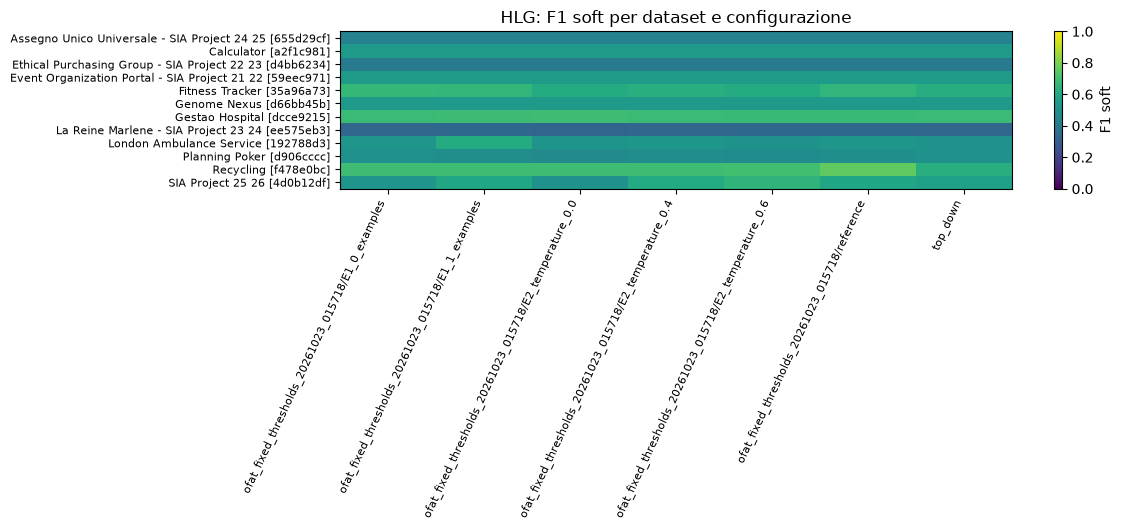

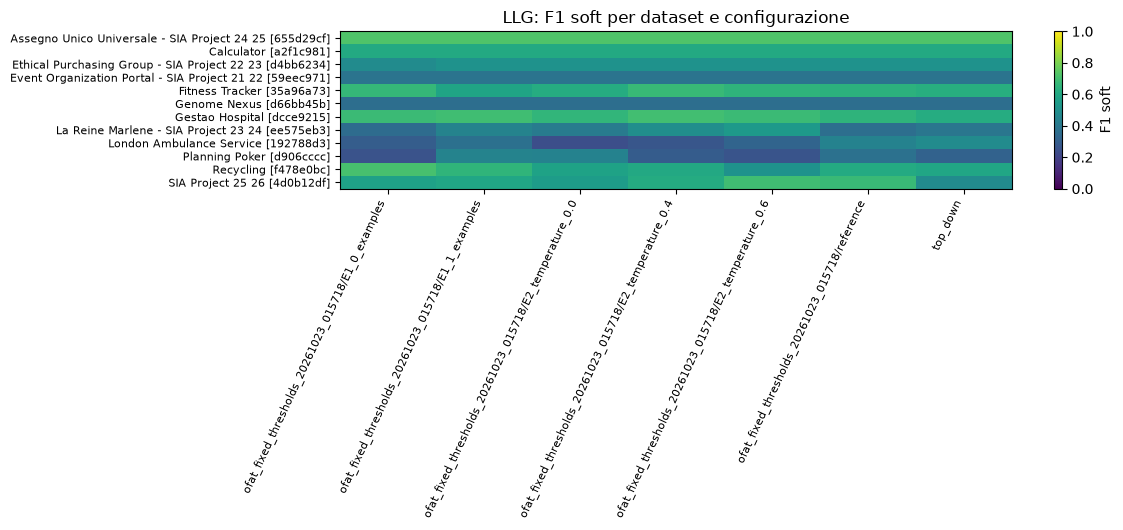

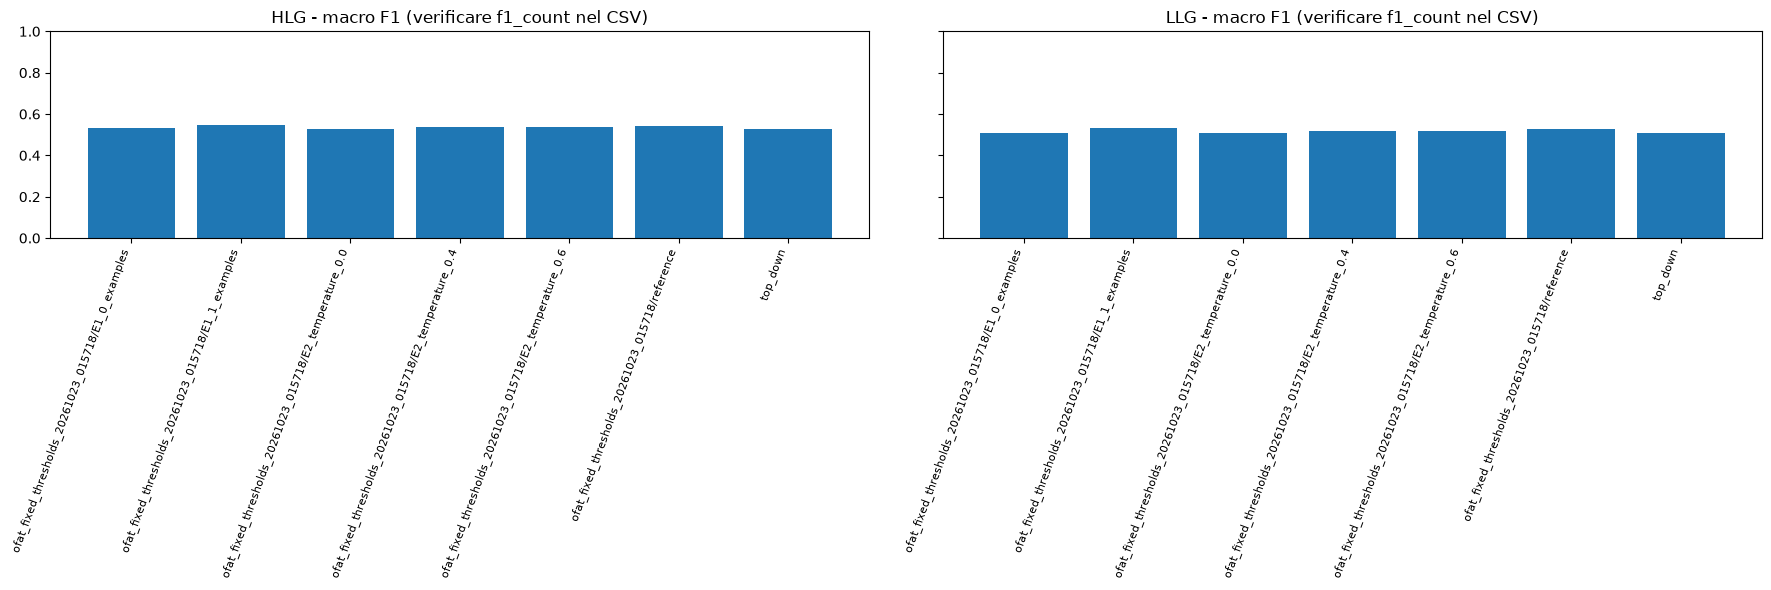

Evaluation completata: C:\Users\agnes\Desktop\TESI FINALE CON EXPERIMENT\LLM_MultiAgentChain_GoalOrientedAPIAlignement\output\evaluation\configuration_comparison\20261023_090732_305510


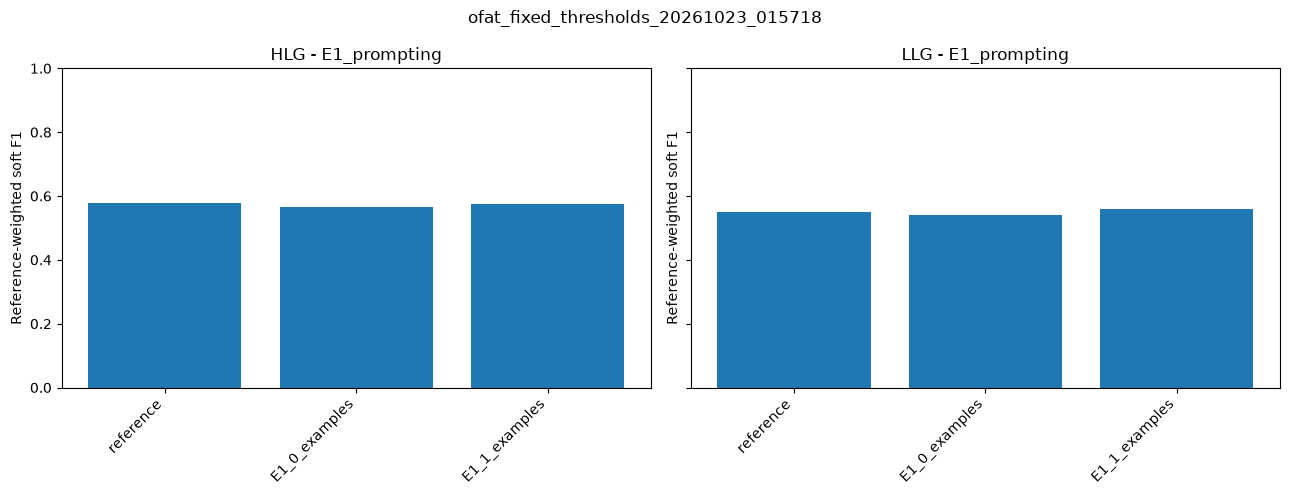

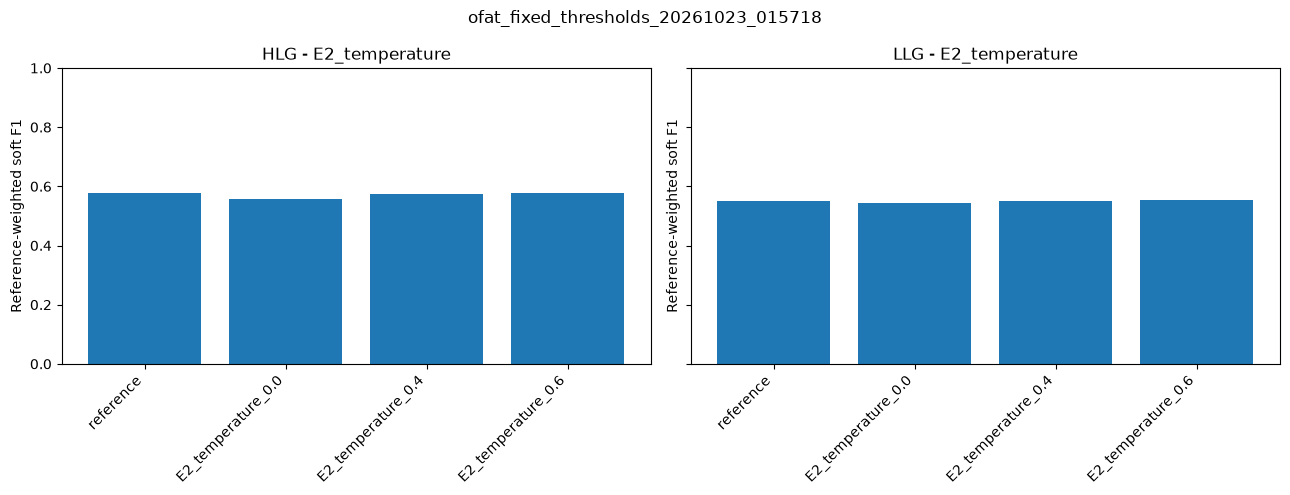

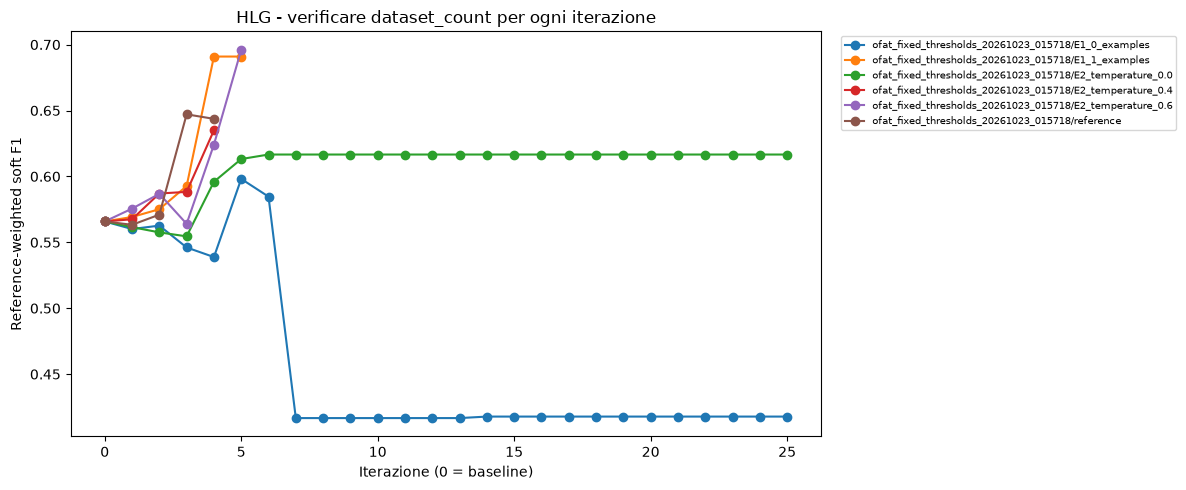

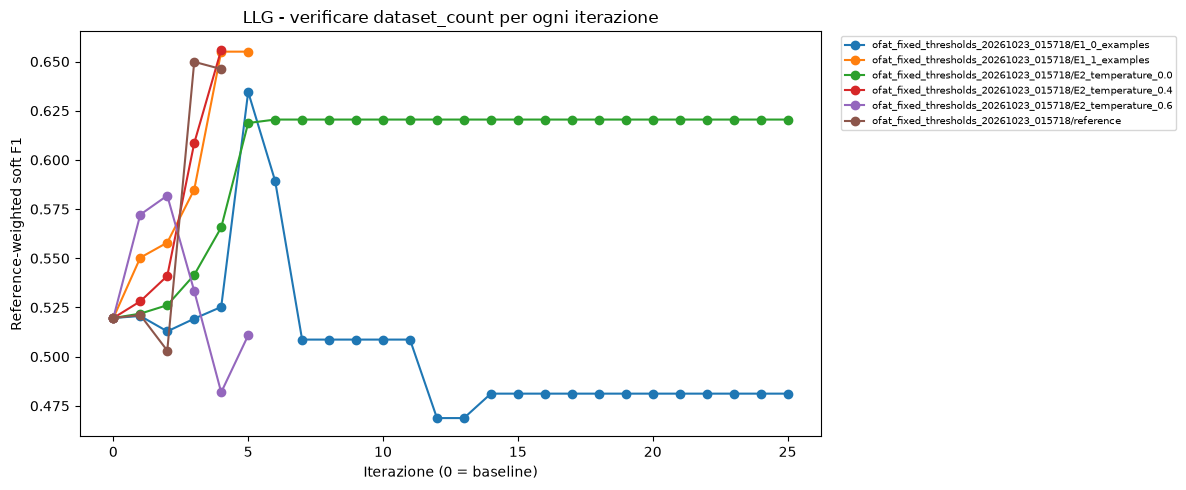

In [11]:
import numpy as np

for level in ("HLG", "LLG"):
    frame = tables["dataset_means"]
    frame = frame[frame.level == level].copy()
    # L'hash breve distingue dataset con input iniziali diversi.
    frame["dataset_cohort"] = frame["dataset"] + " [" + frame["baseline_key"].str[:8] + "]"
    pivot = frame.pivot(index="dataset_cohort", columns="method", values="f1")
    fig, ax = plt.subplots(figsize=(max(12, .8 * len(pivot.columns)), max(5, .45 * len(pivot))))
    cmap = plt.get_cmap("viridis").copy()
    cmap.set_bad("#eeeeee")
    image = ax.imshow(np.ma.masked_invalid(pivot.to_numpy(dtype=float)), vmin=0, vmax=1, aspect="auto", cmap=cmap)
    ax.set_xticks(range(len(pivot.columns)), pivot.columns, rotation=65, ha="right", fontsize=8)
    ax.set_yticks(range(len(pivot.index)), pivot.index, fontsize=8)
    ax.set_title(f"{level}: F1 soft per dataset e configurazione")
    fig.colorbar(image, ax=ax, label="F1 soft")
    fig.tight_layout()
    fig.savefig(REPORT_DIR / f"f1_heatmap_{level}.png", dpi=180, bbox_inches="tight")
    plt.show()

fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)
for ax, level in zip(axes, ("HLG", "LLG")):
    frame = tables["macro_metrics"]
    frame = frame[frame.level == level]
    ax.bar(range(len(frame)), frame.f1_mean)
    ax.set_xticks(range(len(frame)), frame.method, rotation=70, ha="right", fontsize=8)
    ax.set_title(f"{level} - macro F1 (verificare f1_count nel CSV)")
    ax.set_ylim(0, 1)
fig.tight_layout()
fig.savefig(REPORT_DIR / "macro_f1_comparison.png", dpi=180, bbox_inches="tight")
plt.show()
print("Evaluation completata:", REPORT_DIR)

# Confronti dei fattori per ogni suite: legge il disegno effettivo, incluso lo storico.
configurations = tables["configurations"]
weighted = tables["weighted_metrics"]
for suite_id, declared in configurations.groupby("suite_id"):
    families = declared[declared["experiment"] != "reference"]["experiment"].drop_duplicates()
    for family in families:
        ids = declared.loc[declared["experiment"].isin(["reference", family]), "config_id"].tolist()
        fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
        for ax, level in zip(axes, ("HLG", "LLG")):
            subset = weighted[(weighted.suite_id == suite_id) & (weighted.level == level)].set_index("config_id").reindex(ids)
            ax.bar(range(len(ids)), subset["f1"])
            ax.set_xticks(range(len(ids)), ids, rotation=45, ha="right")
            ax.set_title(f"{level} - {family}")
            ax.set_ylabel("Reference-weighted soft F1")
            ax.set_ylim(0, 1)
        fig.suptitle(suite_id)
        fig.tight_layout()
        # IDs come from local manifests; filenames must remain inside REPORT_DIR.
        import re
        label = re.sub(r"[^A-Za-z0-9_.-]+", "_", f"{suite_id}_{family}")
        fig.savefig(REPORT_DIR / f"weighted_f1_{label}.png", dpi=180, bbox_inches="tight")
        plt.show()

# Traiettorie pesate: la prima osservazione usa la baseline dello stesso input.
trajectories = tables["weighted_iteration_metrics"]
for level in ("HLG", "LLG"):
    fig, ax = plt.subplots(figsize=(12, 5))
    for method, frame in trajectories[trajectories.level == level].groupby("method"):
        frame = frame.sort_values("iteration")
        ax.plot(frame["iteration"], frame["f1"], marker="o", label=method)
    ax.set_xlabel("Iterazione (0 = baseline)")
    ax.set_ylabel("Reference-weighted soft F1")
    ax.set_title(f"{level} - verificare dataset_count per ogni iterazione")
    ax.legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.tight_layout()
    fig.savefig(REPORT_DIR / f"weighted_iteration_f1_{level}.png", dpi=180, bbox_inches="tight")
    plt.show()


Output principali:

- `availability.csv`, `coverage.csv`: run incluse, mancanti, fallite o escluse.
- `metrics.csv`, `dataset_means.csv`, `f1_by_dataset.csv`: tutte le metriche HLG/LLG e confronto per progetto.
- `weighted_metrics.csv`, `weighted_by_repetition.csv`, `paired_weighted_metrics.csv`: metriche principali e confronti su coorti appaiate.
- `configurations.csv`: disegno e parametri di tutte le configurazioni lette.
- `macro_metrics.csv`: medie descrittive con numerosita.
- `paired_deltas.csv`, `paired_macro.csv`: confronto con top-down, bottom-up ordinaria e riferimento sperimentale.
- `repeat_variability.csv`: stabilita tra ripetizioni dello stesso dataset.
- `weighted_iteration_metrics.csv`: traiettorie pesate, con numerosita per iterazione.
- `iteration_metrics.csv`, `matches.csv`: dettaglio delle iterazioni e degli abbinamenti finali.
- `evaluation_manifest.json`: provenienza degli input e delle ground truth, metrica e policy della pipeline originale.
- `f1_heatmap_HLG.png`, `f1_heatmap_LLG.png`, `macro_f1_comparison.png`: grafici esportabili.

Per aggiornare il confronto dopo nuove run, eseguire nuovamente tutto il notebook: viene creata una nuova cartella di report.
